# Homework 8: Practicing with Geopandas

## Part 1: Mapping Evictions

Please complete the eviction mapping exercise that we started in class. Remember that you're creating a choropleth map of evictions in NYC in 2024.

In [43]:
%pip install geopandas
%matplotlib inline
%pip install mapclassify

import geopandas as gpd
import pandas as pd

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


Remember the magic command for every notebook

In [44]:
evictions = pd.read_csv("../../w6/input/Evictions_20240615.csv")

evictions.head()

,Court Index Number,Docket Number,Eviction Address,Eviction Apartment Number,Executed Date,Marshal First Name,Marshal Last Name,Residential/Commercial,BOROUGH,Eviction Postcode,Ejectment,Eviction/Legal Possession,Latitude,Longitude,Community Board,Council District,Census Tract,BIN,BBL,NTA
0,318594/23,14150,172 WEST 107TH ST,1W,01/04/2024,David,Smith,Residential,MANHATTAN,10025,Not an Ejectment,Possession,40.800704,-73.964267,7.0,7.0,193.0,1055977.0,1.018610e+09,Morningside Heights
1,016134/18,86658,70 BRUCKNER BLVD.,12E,11/29/2018,Henry,Daley,Residential,BRONX,10454,Not an Ejectment,Possession,40.806321,-73.926264,1.0,8.0,19.0,2116953.0,2.022950e+09,Mott Haven-Port Morris
2,300816/222,209993,23 WYONA STREET,NaN,11/30/2022,Richard,Capuano,Residential,QUEENS,11207,Not an Ejectment,Possession,40.678696,-73.894650,5.0,37.0,1146.0,3389505.0,3.036630e+09,Cypress Hills-City Line
3,K52673/17,94663,601 BRIGHTON BEACH A VE,FRONT GROUND STORE,04/12/2017,Darlene,Barone,Commercial,BROOKLYN,11235,Not an Ejectment,Possession,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,79638/19,173756,540 NEW LOTS AVE,1R,01/18/2024,Alfred,Locascio,Residential,BROOKLYN,11207,Not an Ejectment,Possession,40.663958,-73.888289,5.0,42.0,1122.0,3096753.0,3.043040e+09,East New York (Pennsylvania Ave)


Load up the unemployment data

In [45]:
# set data type
evictions["Executed Date"] = pd.to_datetime(evictions["Executed Date"])

#make a new df with just 2024 entries
evictions_2024 = evictions[(evictions["Executed Date"] >= "2024-01-01") & (evictions["Executed Date"] <= "2024-12-31")]

In [46]:
evictions_2024.dtypes

Court Index Number                   object
Docket Number                         int64
Eviction Address                     object
Eviction Apartment Number            object
Executed Date                datetime64[ns]
Marshal First Name                   object
Marshal Last Name                    object
Residential/Commercial               object
BOROUGH                              object
Eviction Postcode                     int64
Ejectment                            object
Eviction/Legal Possession            object
Latitude                            float64
Longitude                           float64
Community Board                     float64
Council District                    float64
Census Tract                        float64
BIN                                 float64
BBL                                 float64
NTA                                  object
dtype: object

In [47]:
zip_count = evictions_2024.groupby("Eviction Postcode").size().reset_index(name="Count")

zip_count.head()

,Eviction Postcode,Count
0,0,1
1,200,1
2,10001,39
3,10002,45
4,10003,23


<Axes: >

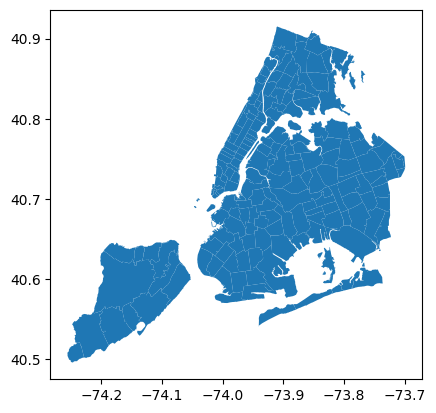

In [48]:
zip_codes = gpd.read_file("nyc-zip-code-tabulation-areas-polygons.geojson")

zip_codes.plot()

In [49]:
zip_count["Eviction Postcode"] = zip_count["Eviction Postcode"].astype(str)

zip_totals = zip_codes.merge(
    zip_count,
    left_on="postalCode",
    right_on="Eviction Postcode"
)

Text(0.5, 1.0, 'Evictions by zip code (2024)')

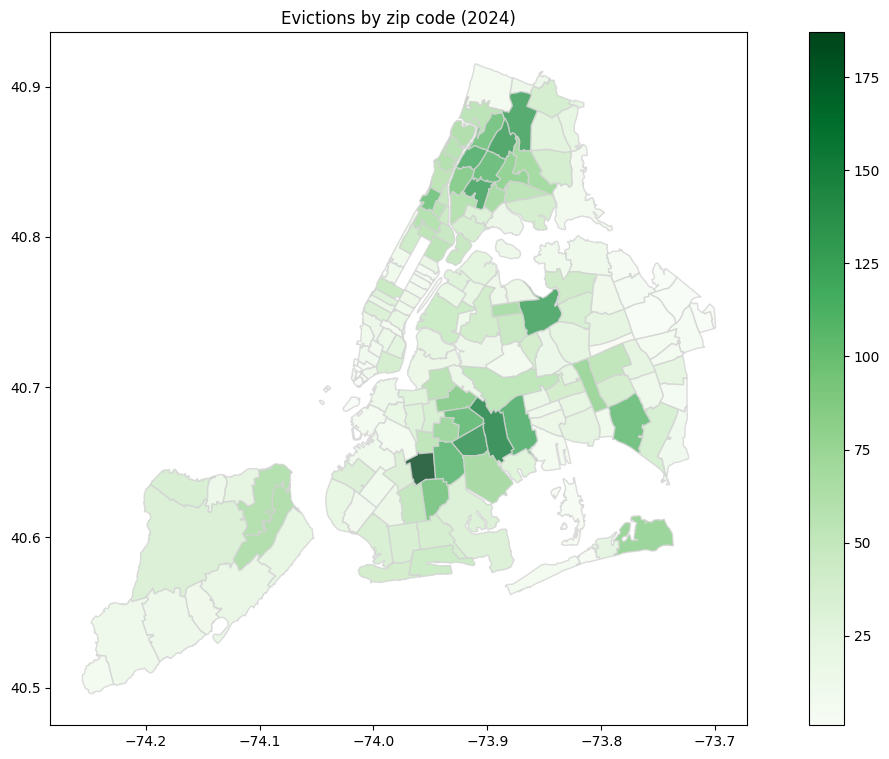

In [50]:
ax = zip_totals.plot(
    column="Count",
    cmap="Greens",
    figsize=(16, 9),
    alpha=0.8,
    legend=True,
    edgecolor="lightgray"
)
ax.set_title("Evictions by zip code (2024)")


## Part 2: Mapping Unemployment

In the data folder for geopandas, you'll find a file called unemployment_2018. Map the unemployment across counties on the continental U.S. using this dataset. Save the final map as a PNG.

In [51]:
# YOUR CODE HERE

unemployment = pd.read_csv("../../w8/output/unemployment_2018.csv")

unemployment.head()

,state_fips,county_fips,combined_fips,name,percent_unemployed
0,1.0,1.0,1001.0,"Autauga County, AL",3.6
1,1.0,3.0,1003.0,"Baldwin County, AL",3.6
2,1.0,5.0,1005.0,"Barbour County, AL",5.2
3,1.0,7.0,1007.0,"Bibb County, AL",4.0
4,1.0,9.0,1009.0,"Blount County, AL",3.5


In [52]:
unemployment.dtypes

state_fips            float64
county_fips           float64
combined_fips         float64
name                   object
percent_unemployed    float64
dtype: object

In [53]:
# remove extra 0 from combined_fips in a new column
unemployment["fips_clean"] = unemployment["combined_fips"].astype(str).str.replace(".0", "", regex=False).str.zfill(5)
unemployment.head()

,state_fips,county_fips,combined_fips,name,percent_unemployed,fips_clean
0,1.0,1.0,1001.0,"Autauga County, AL",3.6,01001
1,1.0,3.0,1003.0,"Baldwin County, AL",3.6,01003
2,1.0,5.0,1005.0,"Barbour County, AL",5.2,01005
3,1.0,7.0,1007.0,"Bibb County, AL",4.0,01007
4,1.0,9.0,1009.0,"Blount County, AL",3.5,01009


In [54]:
unemployment[["combined_fips", "fips_clean"]].head(10)

,combined_fips,fips_clean
0,1001.0,01001
1,1003.0,01003
2,1005.0,01005
3,1007.0,01007
4,1009.0,01009
5,1011.0,01011
6,1013.0,01013
7,1015.0,01015
8,1017.0,01017
9,1019.0,01019


<Axes: >

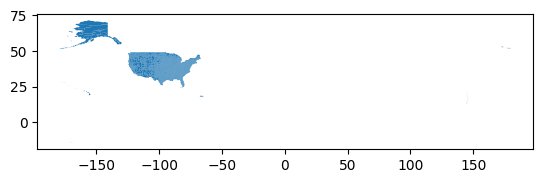

In [55]:
counties = gpd.read_file("../../w8/input/counties.geojson")

counties.plot()

In [56]:
counties[["GEOID"]].head(10)

,GEOID
0,12009
1,06055
2,18065
3,35029
4,10001
5,48481
6,30049
7,30043
8,30007
9,42071


In [57]:
# Remove non continental US
non_continental = ["02", "15", "60", "66", "69", "72", "78"]
continental_counties = counties[~counties["STATEFP"].isin(non_continental)]

# Join unemployment and counties
county_unemployment = continental_counties.merge(
    unemployment,
    left_on="GEOID",
    right_on="fips_clean",
    how="left"
)

print(county_unemployment)

     STATEFP COUNTYFP  COUNTYNS  GEOID         GEOIDFQ       NAME  \
0         12      009  00295749  12009  0500000US12009    Brevard   
1         06      055  00277292  06055  0500000US06055       Napa   
2         18      065  00450359  18065  0500000US18065      Henry   
3         35      029  00933057  35029  0500000US35029       Luna   
4         10      001  00217271  10001  0500000US10001       Kent   
...      ...      ...       ...    ...             ...        ...   
3104      56      015  01605073  56015  0500000US56015     Goshen   
3105      55      107  01581114  55107  0500000US55107       Rusk   
3106      21      079  00516886  21079  0500000US21079    Garrard   
3107      19      177  00465277  19177  0500000US19177  Van Buren   
3108      28      095  00695771  28095  0500000US28095     Monroe   

              NAMELSAD LSAD CLASSFP  MTFCC  ...      AWATER     INTPTLAT  \
0       Brevard County   06      H1  G4020  ...  1403935652  +28.2983112   
1          Napa Cou

Text(0.5, 1.0, 'Unemployment rate by county (2018)')

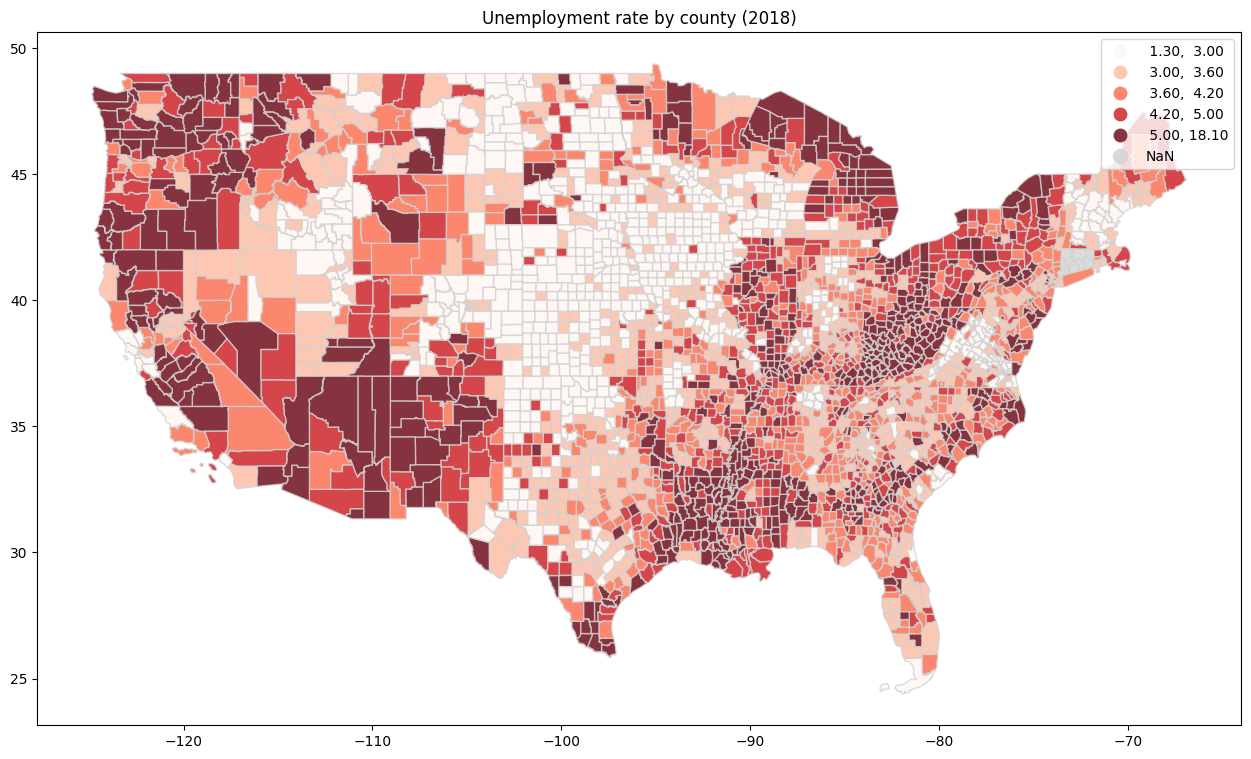

In [64]:
# Visualize

ax = county_unemployment.plot(
    column="percent_unemployed",
    cmap="Reds",
    figsize=(16, 9),
    alpha=0.8,
    legend=True,
    edgecolor="lightgray",
    scheme="quantiles",
    k=5,
    missing_kwds={"facecolor": "lightgrey"},
)
ax.set_title("Unemployment rate by county (2018)")

## Part 3: Reading

To continue our conversation on problematic investigations, let's read this piece from CJR. It doesn't have anything to do with data, per se, but it brings up questions around the ethics of collecting, analyzing, and visualizing data about vulnerable populations. 

https://www.cjr.org/feature/figueroa-street-ethical-duty-care-sex-trafficking-responsible-reporting-new-york-times-nyt-magazine-emily-baumgaertner-nunn.php 

Answer: What are your thoughts on the controversy? What could the Times have done differently to assuague the advocates' concerns? 

(At least 150 words please!)

I'm kind of surprised the photos spurred such controversy, because I think the photos are the least concerning aspect of the piece. Each one seems to almost completely obscure the identity of the subject of the photo, and I don't they are especially distasteful. If anything, I think the tone of the piece at all and its sort of fetishizing, lurking-in-the-dark approach to reporting on sex trafficking is more problematic. I think it perpetuates stigma around low-income communities of color in L.A. without fully presenting the quotidian systems that allow sex trafficking to exist. The cause is probably much closer to home than the author thinks! Also, there's a focus on criminality and arrests throughout the piece, which kind of reinforces the stigma around victims of sex trafficking that the CJR piece discuse